# 01 — Carbon Footprint Exploratory Analysis

Scope 1, 2 & 3 GHG emissions for **EcoNaija Manufacturing Ltd** (a fictional company, synthetic data) using the GHG Protocol activity-based method.

**Questions:**
1. What is the total footprint and how is it split across scopes?
2. Where are the emission hotspots?
3. Is the company on track for a 30% reduction vs the 2023 baseline?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
from carbon import load_activity, load_factors, calculate_emissions, summarise, reduction_vs_baseline

activity = load_activity()
factors = load_factors()
activity.head()

,period,site,activity_type,quantity,unit,year
0,2023-01-01,Lagos HQ,diesel,8334.62,litre,2023
1,2023-01-01,Lagos HQ,petrol,1286.25,litre,2023
2,2023-01-01,Lagos HQ,lpg,186.50,litre,2023
3,2023-01-01,Lagos HQ,refrigerant_r410a,1.38,kg,2023
4,2023-01-01,Lagos HQ,grid_electricity_ng,64256.48,kWh,2023


## 1. Data quality checks

In [2]:
print('Rows:', len(activity))
print('Periods:', activity['period'].min().date(), '→', activity['period'].max().date())
print('Missing values:\n', activity.isna().sum())
activity.groupby('activity_type')['unit'].unique()

Rows: 1116
Periods: 2023-01-01 → 2025-12-01
Missing values:
 period           0
site             0
activity_type    0
quantity         0
unit             0
year             0
dtype: int64


activity_type
business_travel_air_longhaul     [passenger_km]
business_travel_air_shorthaul    [passenger_km]
diesel                                  [litre]
employee_commute_car                       [km]
grid_electricity_ng                       [kWh]
lpg                                     [litre]
natural_gas                                [m3]
petrol                                  [litre]
purchased_goods_spend                     [USD]
refrigerant_r410a                          [kg]
waste_landfill                          [tonne]
Name: unit, dtype: object

## 2. Calculate emissions

In [3]:
emissions = calculate_emissions(activity, factors)
scope_year = summarise(emissions, ['year', 'scope']).pivot(index='year', columns='scope', values='tco2e')
scope_year.columns = [f'Scope {c}' for c in scope_year.columns]
scope_year['Total'] = scope_year.sum(axis=1)
scope_year.round(1)

,Scope 1,Scope 2,Scope 3,Total
year,,,,
2023,1249.0,1021.7,2287.7,4558.4
2024,1192.3,972.2,2186.9,4351.4
2025,1148.5,944.1,2020.5,4113.0


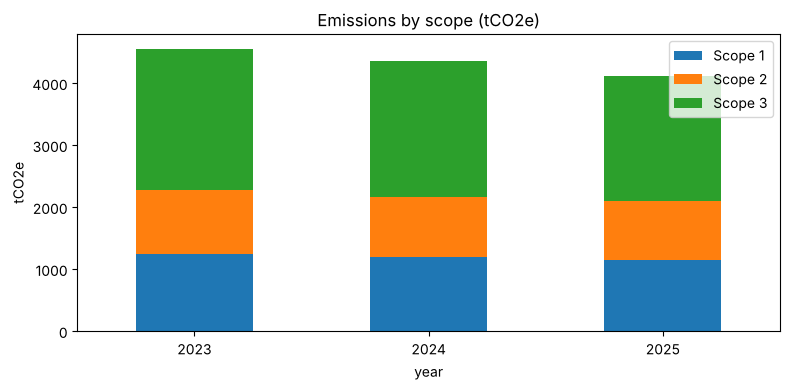

In [4]:
scope_year.drop(columns='Total').plot(kind='bar', stacked=True, figsize=(8, 4), title='Emissions by scope (tCO2e)')
plt.ylabel('tCO2e'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. Hotspots

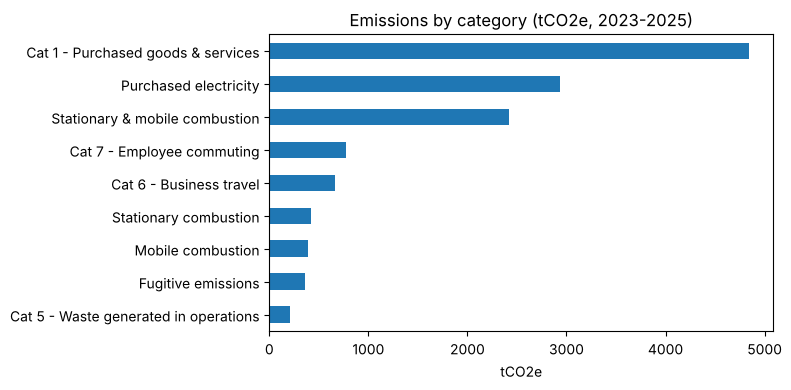

,category,tco2e,share_%
0,Cat 1 - Purchased goods & services,4844.331559,37.2
6,Purchased electricity,2937.916180,22.6
7,Stationary & mobile combustion,2418.700068,18.6
3,Cat 7 - Employee commuting,777.948099,6.0
2,Cat 6 - Business travel,660.248997,5.1
8,Stationary combustion,420.435955,3.2
5,Mobile combustion,392.679372,3.0
4,Fugitive emissions,358.029360,2.7
1,Cat 5 - Waste generated in operations,212.480330,1.6


In [5]:
hot = summarise(emissions, ['category']).sort_values('tco2e')
hot['share_%'] = (hot['tco2e'] / hot['tco2e'].sum() * 100).round(1)
hot.plot(x='category', y='tco2e', kind='barh', legend=False, figsize=(8, 4), title='Emissions by category (tCO2e, 2023-2025)')
plt.xlabel('tCO2e'); plt.ylabel(''); plt.tight_layout(); plt.show()
hot.sort_values('tco2e', ascending=False)

## 4. Progress vs 30% reduction target

In [6]:
progress = reduction_vs_baseline(emissions, baseline_year=2023)
progress.round(1)

,year,tco2e,pct_change_vs_baseline
0,2023,4558.4,0.0
1,2024,4351.4,-4.5
2,2025,4113.0,-9.8


## 5. Key findings & recommendations (synthetic data)

- **Scope 3 is roughly half the footprint** — purchased goods & services is the single biggest hotspot, so supplier engagement and spend-based → activity-based data upgrades are the priority.
- **Scope 2 (grid electricity) is the second-largest source** — rooftop solar / PPAs at Port Harcourt Plant would have the largest single-site impact.
- **Diesel generators** drive Scope 1; hybrid solar-battery systems would cut both emissions and fuel cost.
- Emissions fell ~10% from 2023 to 2025 — **not on track** for a 30% cut by 2030 without new interventions.

*Next:* scenario modelling of reduction levers (see TASK.md).